In [1]:
# Stock Price Prediction of Apple Using Linear Regression and Technical Indicators

In [2]:
import yfinance as yf

In [3]:
# Step 1: Download the data from Yahoo Finance
tickers = ['AAPL', 'AMZN', 'MSFT', 'QQQ', '^GSPC']
df = yf.download(tickers, start = '2020-01-01', end = '2025-12-31')['Close']
df

[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,MSFT,QQQ,^GSPC
Date,,,,,
2020-01-02,72.271545,94.900497,151.544266,207.872284,3257.850098
2020-01-03,71.568932,93.748497,149.657272,205.968155,3234.850098
2020-01-06,72.139206,95.143997,150.044128,207.295258,3246.280029
2020-01-07,71.799950,95.343002,148.676025,207.266403,3237.179932
2020-01-08,72.954910,94.598503,151.044220,208.824310,3253.050049
...,...,...,...,...,...
2025-12-23,271.620667,232.139999,483.780792,619.998474,6909.790039
2025-12-24,273.066711,232.380005,484.943390,621.812256,6932.049805
2025-12-26,272.657837,232.520004,484.635345,621.772461,6929.939941


In [4]:
# Step 2: Perform Feature Engineering

# Considering Yesterday's Value
df['AAPL(t-1)'] = df['AAPL'].shift(1)
df['AMZN(t-1)'] = df['AMZN'].shift(1)
df['MSFT(t-1)'] = df['MSFT'].shift(1)
df['QQQ(t-1)'] = df['QQQ'].shift(1)
df['^GSPC(t-1)'] = df['^GSPC'].shift(1)

# Moving Avg (MA): Technical Indicator - It helps you understand the sho
df['AAPL_MA_5'] = df['AAPL'].rolling(window=5).mean()
df['AMZN_MA_5'] = df['AMZN'].rolling(window=5).mean()
df['MSFT_MA_5'] = df['MSFT'].rolling(window=5).mean()
df['QQQ_MA_5'] = df['QQQ'].rolling(window=5).mean()
df['^GSPC_MA_5'] = df['^GSPC'].rolling(window=5).mean()

# Set Y Variable - Next day
df['Target'] = df['AAPL'].shift(-1)
df = df.dropna()

In [5]:
df.columns

Index(['AAPL', 'AMZN', 'MSFT', 'QQQ', '^GSPC', 'AAPL(t-1)', 'AMZN(t-1)',
       'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5',
       'MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5', 'Target'],
      dtype='str', name='Ticker')

In [6]:
import statsmodels.api as sm
X = df[['AAPL(t-1)', 'AMZN(t-1)',
'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5', 'MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5']]
Y = df['Target']
X_const = sm.add_constant(X) # Intercept Term

# Train the Model
model = sm.OLS(Y, X_const).fit()

# Summary
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Target   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                 2.099e+04
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:59:40   Log-Likelihood:                -4265.3
No. Observations:                1502   AIC:                             8553.
Df Residuals:                    1491   BIC:                             8611.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.9471      1.224      1.591      0.112      -0.454       4.348
AAPL(t-1)      0.5852      0.068      8.545      0.000       0.451       0.720
AMZN(t-1)      0.0408      0.063      0.648      0.517      -0.083       0.164
MSFT(t-1)     -0.0712      0.046     -1.556      0.120      -0.161       0.019
QQQ(t-1)       0.0461      0.095      0.483      0.629      -0.141       0.233
^GSPC(t-1)     0.0042      0.008      0.548      0.584      -0.011       0.019
AAPL_MA_5      0.3808      0.069      5.505      0.000       0.245       0.516
AMZN_MA_5     -0.0504      0.064     -0.787      0.432      -0.176       0.075
MSFT_MA_5      0.0844      0.046      1.824      0.068      -0.006       0.175
QQQ_MA_5      -0.0309      0.097     -0.318      0.751      -0.222       0.160
^GSPC_MA_5    -0.0051      0.008     -0.666      0.505      -0.020       0.010
==============================================================================
Omnibus:                      215.045   Durbin-Watson:                   0.783
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1465.937
Skew:                          -0.464   Prob(JB):                         0.00
Kurtosis:                       7.750   Cond. No.                     7.63e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.63e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [7]:
import statsmodels.api as sm
X = df[['AAPL(t-1)', '^GSPC(t-1)']] # Dropping AAPL_MA_5
Y = df['Target']
X_const = sm.add_constant(X) # Intercept Term

# Train the Model
model = sm.OLS(Y, X_const).fit()

# Summary
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Target   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                 1.006e+05
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:59:40   Log-Likelihood:                -4301.0
No. Observations:                1502   AIC:                             8608.
Df Residuals:                    1499   BIC:                             8624.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.9816      0.587     -1.672      0.095      -2.133       0.170
AAPL(t-1)      0.9721      0.007    141.914      0.000       0.959       0.986
^GSPC(t-1)     0.0013      0.000      3.858      0.000       0.001       0.002
==============================================================================
Omnibus:                      212.065   Durbin-Watson:                   0.959
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1744.787
Skew:                          -0.377   Prob(JB):                         0.00
Kurtosis:                       8.226   Cond. No.                     2.52e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.52e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [8]:
import pandas as pd
df_train_predict = pd.DataFrame()
df_train_predict['Actual'] = df['Target']
df_train_predict['Predicted'] = model.predict(X_const)
df_train_predict

,Actual,Predicted
Date,,
2020-01-08,74.504547,72.937393
2020-01-09,74.672958,74.080363
2020-01-10,76.268295,75.614366
2020-01-13,75.238426,75.766183
2020-01-14,74.916023,77.346051
...,...,...
2025-12-22,271.620667,273.037613
2025-12-23,273.066711,270.475930
2025-12-24,272.657837,271.863363


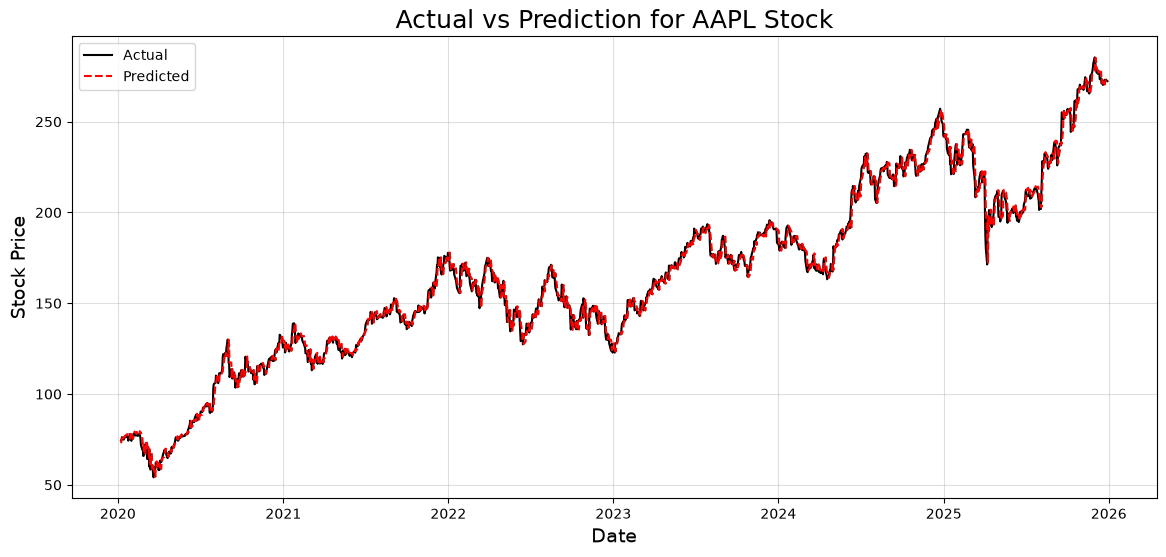

In [9]:
# Plot between Actual vs Predicted Value

import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_train_predict.index, df_train_predict['Actual'], label = 'Actual', color = 'black')
plt.plot(df_train_predict.index, df_train_predict['Predicted'], label = 'Predicted', color = 'red', linestyle = '--')
plt.title("Actual vs Prediction for AAPL Stock", fontsize = 18)
plt.xlabel("Date", fontsize = 14)
plt.ylabel("Stock Price", fontsize = 14)
plt.grid(alpha = 0.4)
plt.legend()
plt.show()

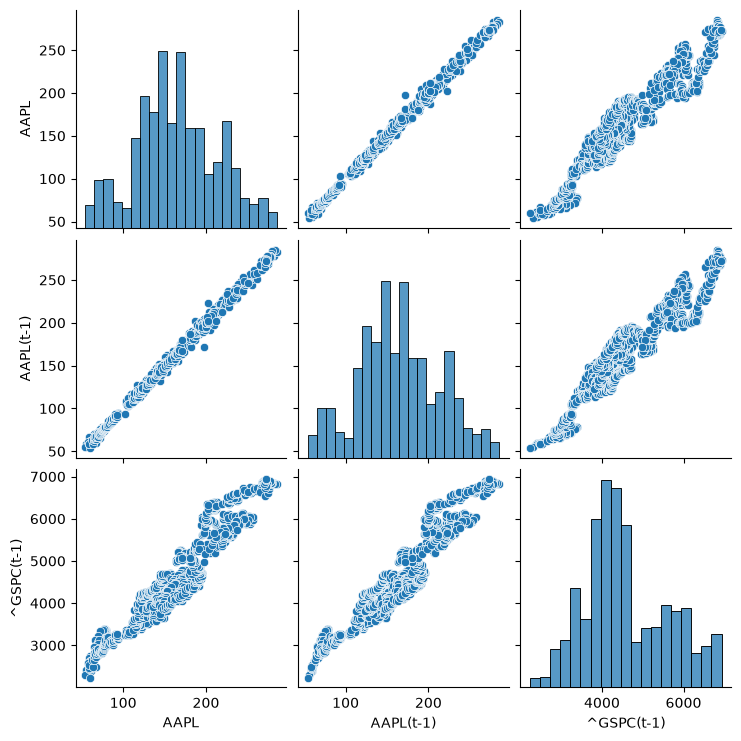

In [10]:
# Assumptions of Linear Regression:

import seaborn as sns
df = df[['AAPL', 'AAPL(t-1)', '^GSPC(t-1)']]
sns.pairplot(df)

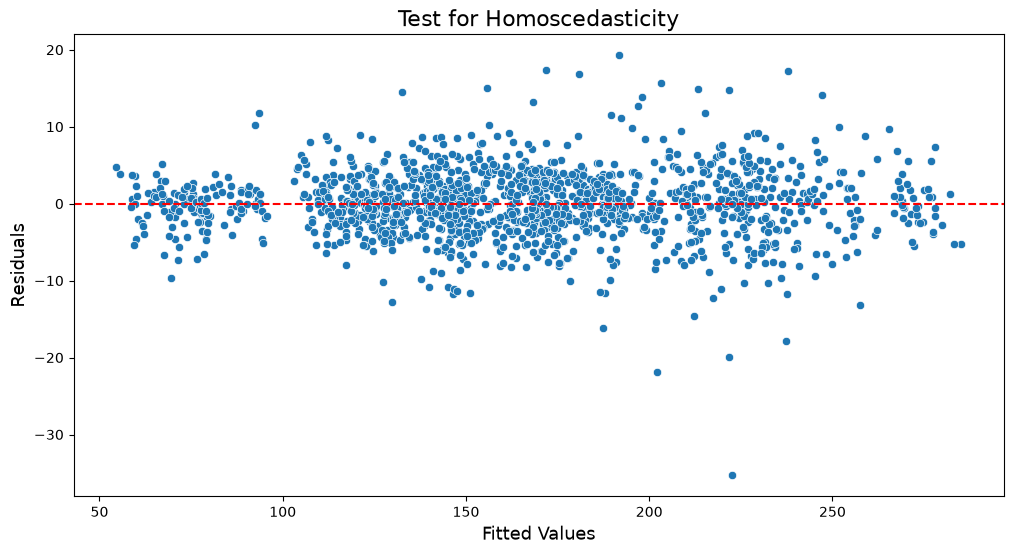

In [11]:
# 2) Homoscedasticity: Fitting Residual with the predicted value
residual = model.resid 
fitted = model.fittedvalues  
plt.figure(figsize = (12,6))
sns.scatterplot(x = fitted, y = residual)
plt.axhline(0, color = 'red', linestyle = '--')
plt.title('Test for Homoscedasticity', fontsize = 16)
plt.xlabel('Fitted Values', fontsize = 13)
plt.ylabel('Residuals', fontsize = 13)
plt.show()

In [12]:
X_const.columns

Index(['const', 'AAPL(t-1)', '^GSPC(t-1)'], dtype='str')

In [13]:
# 3) Multicollinearity => VIF (Variance Inflation Factor)

from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.DataFrame()
vif['Features'] = X_const.columns
vif['VIF'] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
vif = vif[1:]
vif

,Features,VIF
1,AAPL(t-1),9.494054
2,^GSPC(t-1),9.494054


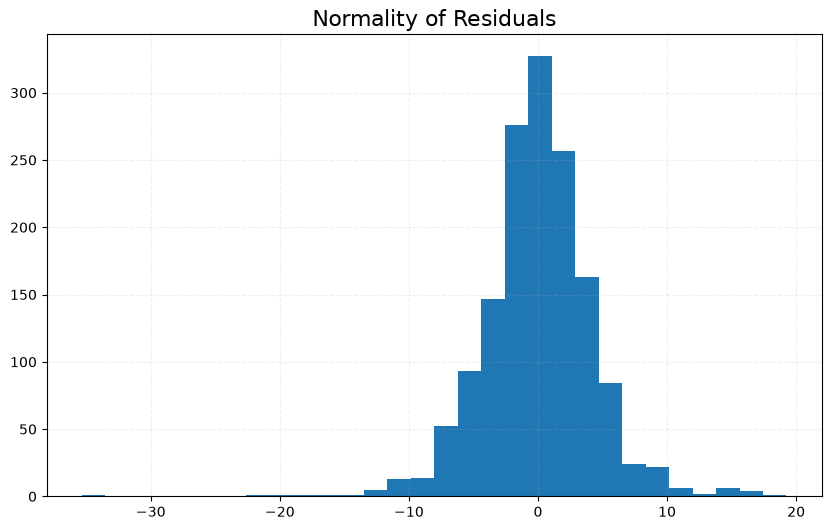

In [14]:
plt.figure(figsize = (10,6))
plt.hist(residual, bins = 30)
plt.title("Normality of Residuals", fontsize = 16)
plt.grid(linestyle = '--', alpha = 0.2)
plt.show()

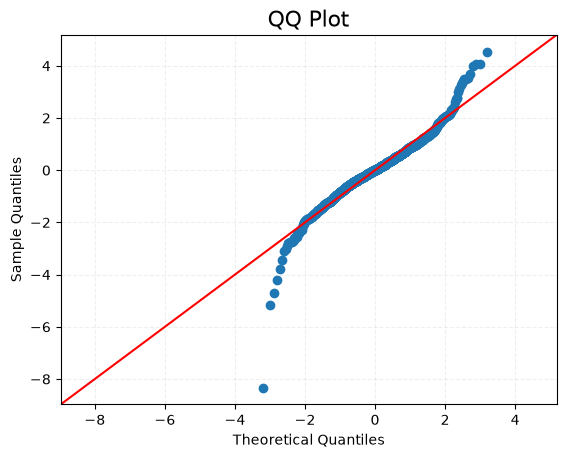

In [15]:
# QQ Plot for testing Normality of Residuals

import statsmodels.api as sm
sm.qqplot(residual, line = '45', fit = True)
plt.title('QQ Plot', fontsize = 16)
plt.grid(linestyle = '--', alpha = 0.2)
plt.show()

In [16]:
# Test 5: Auto correlation of Residual: Durbin Watson Test

from statsmodels.stats.stattools import durbin_watson
dw = durbin_watson(residual)
print(dw)

0.9592771849641176


In [17]:
# Predict the Stock Price for the Year 2026se
tickers = ['AAPL', '^GSPC']
df = yf.download(tickers, start = '2026-01-01', end = '2026-07-31')['Close']
df.head()

[*********************100%***********************]  2 of 2 completed


Ticker,AAPL,^GSPC
Date,,
2026-01-02,270.274353,6858.470215
2026-01-05,266.534546,6902.049805
2026-01-06,261.647766,6944.819824
2026-01-07,259.623322,6920.930176
2026-01-08,258.336853,6921.459961


In [18]:
df['AAPL(t-1)'] = df['AAPL'].shift(1)
df['^GSPC(t-1)'] = df['^GSPC'].shift(1)
df = df.dropna()
df.head()

Ticker,AAPL,^GSPC,AAPL(t-1),^GSPC(t-1)
Date,,,,
2026-01-05,266.534546,6902.049805,270.274353,6858.470215
2026-01-06,261.647766,6944.819824,266.534546,6902.049805
2026-01-07,259.623322,6920.930176,261.647766,6944.819824
2026-01-08,258.336853,6921.459961,259.623322,6920.930176
2026-01-09,258.665924,6966.279785,258.336853,6921.459961


In [19]:
X_test = df[['AAPL(t-1)', '^GSPC(t-1)']]
X_test = sm.add_constant(X_test)
df_result = pd.DataFrame()
df_result['Actual'] = df['AAPL']
df_result['Predicted'] = model.predict(X_test)
df_result.head()

,Actual,Predicted
Date,,
2026-01-05,266.534546,270.489254
2026-01-06,261.647766,266.909143
2026-01-07,259.623322,262.212995
2026-01-08,258.336853,260.214567
2026-01-09,258.665924,258.964627


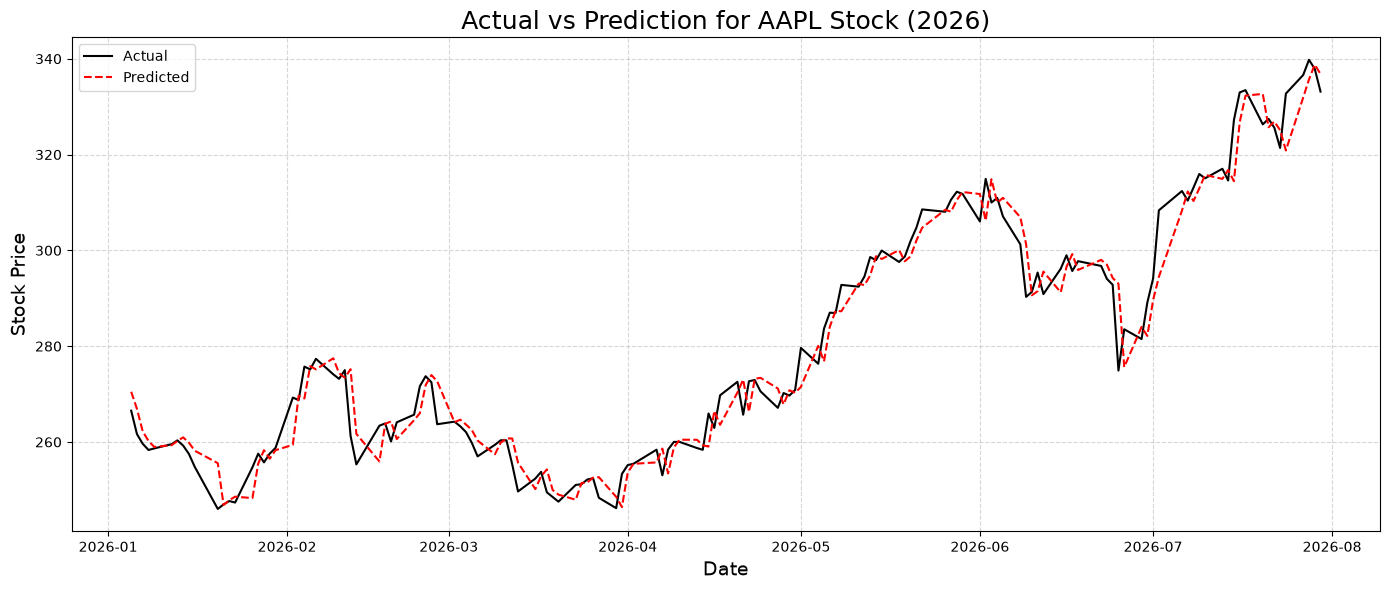

In [20]:
# Plot between Actual vs Predicted Value

import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_result.index, df_result['Actual'], label = 'Actual', color = 'black') 
plt.plot(df_result.index, df_result['Predicted'], label = 'Predicted', color = 'red', linestyle = '--')
plt.title("Actual vs Prediction for AAPL Stock (2026)", fontsize = 18 )
plt.xlabel("Date", fontsize = 14)
plt.ylabel("Stock Price", fontsize = 14)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.legend()
plt.show()

In [21]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Calculate mse
mse = mean_squared_error(df_result['Actual'], df_result['Predicted'])
rmse = np.sqrt(mse)
print(rmse, mse)

4.677743629053162 21.88128545914745


In [22]:
# Step 1: Download the data from Yahoo Finance
tickers = ['AAPL', 'AMZN', 'MSFT', 'QQQ', '^GSPC']
df = yf.download(tickers, start = '2020-01-01', end = '2026-07-31')['Close']
df

[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,MSFT,QQQ,^GSPC
Date,,,,,
2020-01-02,72.271545,94.900497,151.544266,207.872253,3257.850098
2020-01-03,71.568909,93.748497,149.657303,205.968185,3234.850098
2020-01-06,72.139191,95.143997,150.044128,207.295258,3246.280029
2020-01-07,71.799950,95.343002,148.676086,207.266403,3237.179932
2020-01-08,72.954926,94.598503,151.044174,208.824295,3253.050049
...,...,...,...,...,...
2026-07-24,332.733032,232.110001,380.982819,683.517761,7411.979980
2026-07-27,336.619690,231.389999,388.368896,681.409973,7413.180176
2026-07-28,339.786926,230.860001,392.610901,674.786865,7428.779785


In [23]:
# Considering Yesterday's Value
df['AAPL(t-1)'] = df['AAPL'].shift(1)
df['AMZN(t-1)'] = df['AMZN'].shift(1)
df['MSFT(t-1)'] = df['MSFT'].shift(1)
df['QQQ(t-1)'] = df['QQQ'].shift(1)
df['^GSPC(t-1)'] = df['^GSPC'].shift(1)

# Moving Avg (MA): Technical Indicator - It helps you understand the sho
df['AAPL_MA_5'] = df['AAPL'].rolling(window=5).mean()
df['AMZN_MA_5'] = df['AMZN'].rolling(window=5).mean()
df['MSFT_MA_5'] = df['MSFT'].rolling(window=5).mean()
df['QQQ_MA_5'] = df['QQQ'].rolling(window=5).mean()
df['^GSPC_MA_5'] = df['^GSPC'].rolling(window=5).mean()

# Set Y Variable - Next day
df['Target'] = df['AAPL'].shift(-1)
df = df.dropna()
df

Ticker,AAPL,AMZN,MSFT,QQQ,^GSPC,AAPL(t-1),AMZN(t-1),MSFT(t-1),QQQ(t-1),^GSPC(t-1),AAPL_MA_5,AMZN_MA_5,MSFT_MA_5,QQQ_MA_5,^GSPC_MA_5,Target
Date,,,,,,,,,,,,,,,,
2020-01-08,72.954926,94.598503,151.044174,208.824295,3253.050049,71.799950,95.343002,148.676086,207.266403,3237.179932,72.146904,94.746899,150.193192,207.445279,3245.842041,74.504532
2020-01-09,74.504532,95.052498,152.931168,210.593796,3274.699951,72.954926,94.598503,151.044174,208.824295,3253.050049,72.593501,94.777299,150.470572,207.989587,3249.212012,74.672966
2020-01-10,74.672966,94.157997,152.223557,210.055237,3265.350098,74.504532,95.052498,152.931168,210.593796,3274.699951,73.214313,94.859200,150.983823,208.806998,3255.312012,76.268311
2020-01-13,76.268311,94.565002,154.053925,212.478622,3288.129883,74.672966,94.157997,152.223557,210.055237,3265.350098,74.040137,94.743401,151.785782,209.843671,3263.681982,75.238464
2020-01-14,75.238464,93.472000,152.968933,211.641983,3283.149902,76.268311,94.565002,154.053925,212.478622,3288.129883,74.727840,94.369200,152.644351,210.718787,3272.875977,74.916008
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-07-23,321.382843,233.660004,380.863007,691.239746,7408.299805,325.609192,244.850006,389.606567,704.615723,7498.959961,326.842114,244.656003,392.417267,698.805823,7463.485937,332.733032
2026-07-24,332.733032,232.110001,380.982819,683.517761,7411.979980,321.382843,233.660004,380.863007,691.239746,7408.299805,326.698242,241.632004,389.997827,696.588135,7454.343945,336.619690
2026-07-27,336.619690,231.389999,388.368896,681.409973,7413.180176,332.733032,232.110001,380.982819,683.517761,7411.979980,328.760468,237.912003,387.364783,693.803040,7448.324023,339.786926


In [24]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

In [25]:
X = df[['AAPL(t-1)', 'AMZN(t-1)',
'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5',
'MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5']]
Y = df['Target']

In [26]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.05, shuffle = False)
                                                

In [27]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha = 10)
lasso.fit(X_train, Y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [28]:
# Step 5: Get Intercept and Coeff for Lasso Regression

coefficients = lasso.coef_
coefficients
intercept = lasso.intercept_
intercept
coeff_df = pd.DataFrame({'Feature':X.columns, 'Coefficients':coefficients})
coeff_df

,Feature,Coefficients
0,AAPL(t-1),0.654305
1,AMZN(t-1),-0.000000
2,MSFT(t-1),0.000000
3,QQQ(t-1),0.000000
4,^GSPC(t-1),0.002218
5,AAPL_MA_5,0.276670
6,AMZN_MA_5,-0.000000
7,MSFT_MA_5,0.009601
8,QQQ_MA_5,0.000000
9,^GSPC_MA_5,0.000000


In [29]:
# Step 6: Predict using Lasso Regression

y_pred = lasso.predict(X_test)
y_pred

array([246.40270183, 251.65212003, 253.13938805, 253.9316159 ,
       256.32143114, 253.12194642, 257.29251616, 258.67074259,
       258.68773515, 258.33975688, 258.76451866, 264.1026116 ,
       262.80209389, 268.28053654, 270.54965089, 266.3697664 ,
       271.65102431, 271.80472571, 270.0949213 , 268.12167905,
       269.88665671, 269.39751497, 270.81234376, 277.08812125,
       275.5708911 , 281.43887845, 284.7623098 , 285.3837605 ,
       290.24986408, 290.63352176, 292.61904707, 295.96416505,
       296.06906066, 297.49002693, 296.16447631, 297.01073307,
       299.72608142, 302.01582813, 305.14853328, 305.57886422,
       307.80940532, 309.4411625 , 309.12504921, 305.83843319,
       311.66748236, 308.24482833, 308.62160913, 305.27649608,
       300.09813188, 291.78096617, 291.25418487, 293.23831247,
       290.07288471, 294.26567485, 296.22022702, 293.97764346,
       295.78308599, 294.90102935, 292.49637732, 290.48280675,
       277.96057179, 282.75279697, 281.33593979, 286.55

In [30]:
# Step 7: Create a dataframe with Actual and Predicted Values

df_result = pd.DataFrame({'Actual': Y_test, 'Predicted': y_pred})
df_result

,Actual,Predicted
Date,,
2026-03-31,255.174637,246.402702
2026-04-01,255.464111,251.652120
2026-04-02,258.398865,253.139388
2026-04-06,253.048416,253.931616
2026-04-07,258.438812,256.321431
...,...,...
2026-07-23,332.733032,322.332115
2026-07-24,336.619690,319.302681
2026-07-27,339.786926,327.282610


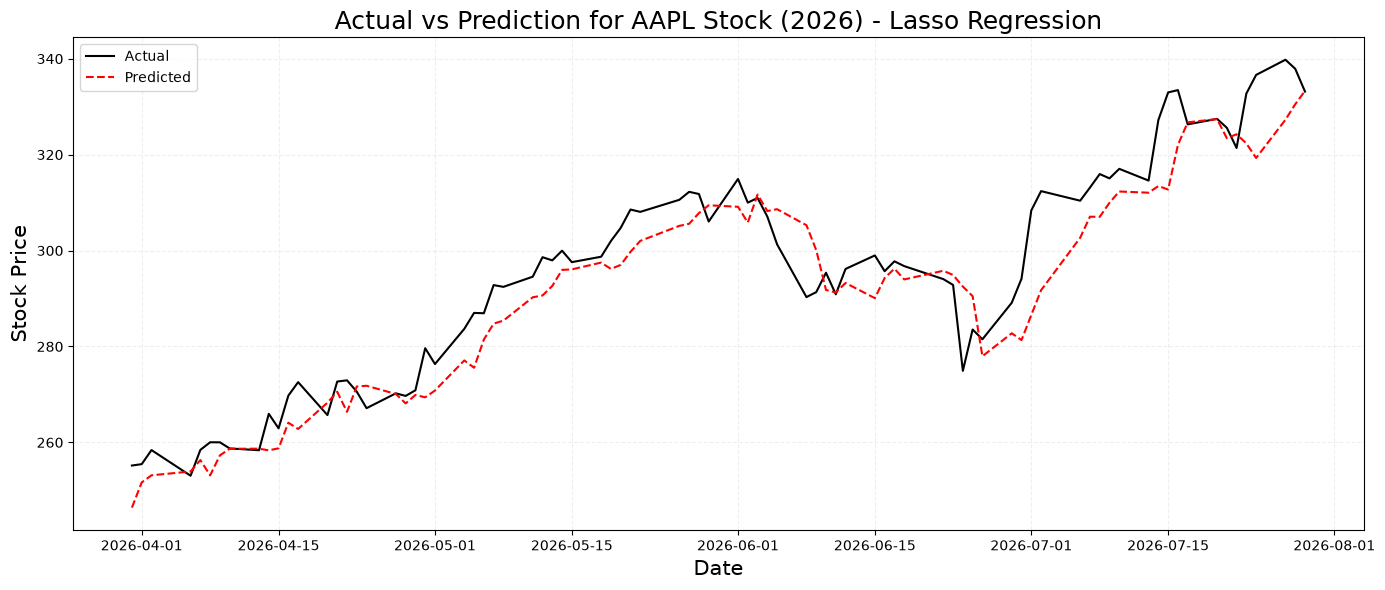

In [31]:
# Step 8: Plot Actual & Predicted Values

import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_result.index, df_result['Actual'], label = 'Actual', color = 'black') 
plt.plot(df_result.index, df_result['Predicted'], label = 'Predicted', color = 'red', linestyle = '--') 
plt.title("Actual vs Prediction for AAPL Stock (2026) - Lasso Regression", fontsize = 18)
plt.xlabel("Date", fontsize = 15)
plt.ylabel("Stock Price", fontsize = 15)
plt.grid(True, linestyle = '--', alpha = 0.2)
plt.tight_layout()
plt.legend()
plt.show()

In [32]:
from sklearn.metrics import r2_score, mean_squared_error
r2 = r2_score(Y_test, y_pred)
print("R square", r2)
mse = mean_squared_error(Y_test, y_pred)
print("mse",mse)
rmse = np.sqrt(mse)
print("rmse", rmse)

R square 0.8870290743120215
mse 59.69397917215883
rmse 7.726187880977192


In [33]:
# Ridge Regression
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

In [34]:
X = df[['AAPL(t-1)', 'AMZN(t-1)',
'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5','MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5']]
Y = df['Target']

In [35]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.05, shuffle = False)

In [36]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha = 10)
ridge.fit(X_train, Y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' t

In [37]:
coefficients = ridge.coef_
coefficients
intercept = ridge.intercept_
intercept
coeff_df = pd.DataFrame({'Feature':X.columns, 'Coefficients':coefficients})
coeff_df

,Feature,Coefficients
0,AAPL(t-1),0.623497
1,AMZN(t-1),0.084370
2,MSFT(t-1),-0.094851
3,QQQ(t-1),-0.001072
4,^GSPC(t-1),0.005773
5,AAPL_MA_5,0.340467
6,AMZN_MA_5,-0.093592
7,MSFT_MA_5,0.108744
8,QQQ_MA_5,0.015681
9,^GSPC_MA_5,-0.006656


In [38]:
# Step 6: Predict using Ridge Regression

y_pred = ridge.predict(X_test)
y_pred

array([245.99008592, 251.25239012, 253.15073474, 253.45782647,
       256.00867179, 252.78641697, 257.25253039, 259.1327248 ,
       259.17744505, 257.43847053, 258.18835744, 262.20111395,
       260.9310965 , 266.80561258, 269.79420173, 265.51869526,
       270.35097737, 271.7845828 , 270.04164712, 267.86138338,
       268.54883389, 268.34261224, 271.50065262, 276.8981174 ,
       275.25126083, 281.02164143, 284.74342456, 284.29260535,
       289.92911145, 290.39611103, 292.4954186 , 296.31655736,
       296.36048861, 296.30925352, 295.35905798, 296.57394058,
       299.92182775, 302.52343439, 305.41933219, 305.87348881,
       308.89753245, 310.01258128, 308.08463718, 303.9574645 ,
       311.65614158, 309.33349978, 309.9373924 , 305.90884455,
       300.71734619, 292.99823857, 291.54412991, 294.19941928,
       290.58477905, 294.59366144, 296.46990194, 294.39943169,
       296.66226319, 295.7209986 , 292.25641915, 290.55589273,
       279.16116141, 281.95018534, 281.66226272, 286.40

In [39]:
# Step 7: Create a dataframe with Actual and Predicted Values

df_result = pd.DataFrame({'Actual': Y_test, 'Predicted': y_pred})
df_result

,Actual,Predicted
Date,,
2026-03-31,255.174637,245.990086
2026-04-01,255.464111,251.252390
2026-04-02,258.398865,253.150735
2026-04-06,253.048416,253.457826
2026-04-07,258.438812,256.008672
...,...,...
2026-07-23,332.733032,323.540771
2026-07-24,336.619690,320.278890
2026-07-27,339.786926,328.003432


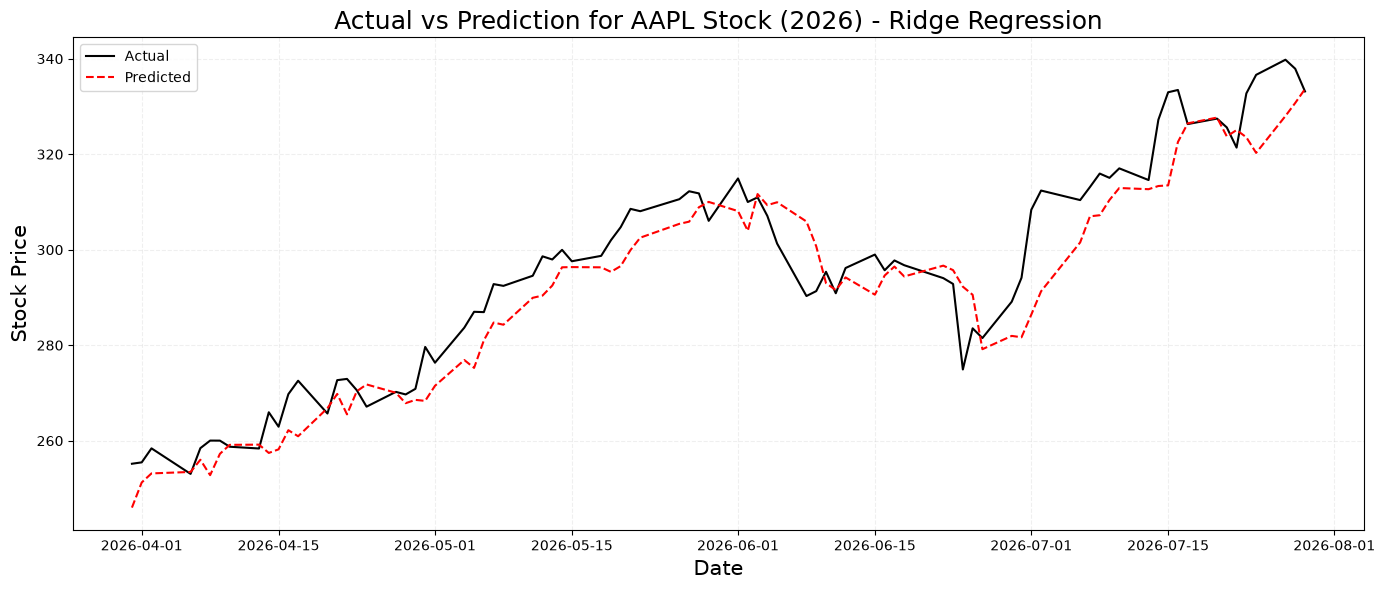

In [40]:
# Step 8: Plot Actual & Predicted Values

import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_result.index, df_result['Actual'], label = 'Actual', color = 'black')
plt.plot(df_result.index, df_result['Predicted'], label = 'Predicted', color = 'red', linestyle = '--')
plt.title("Actual vs Prediction for AAPL Stock (2026) - Ridge Regression", fontsize = 18)
plt.xlabel("Date", fontsize = 15)
plt.ylabel("Stock Price", fontsize = 15)
plt.grid(True, linestyle = '--', alpha = 0.2)
plt.tight_layout()
plt.legend()
plt.show()

In [41]:
from sklearn.metrics import r2_score, mean_squared_error
r2 = r2_score(Y_test, y_pred)
print("R square", r2)
mse = mean_squared_error(Y_test, y_pred)
print("mse",mse)
rmse = np.sqrt(mse)
print("rmse", rmse)

R square 0.883699743660743
mse 61.45320167427023
rmse 7.8392092505730595


In [42]:
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

In [43]:
X = df[['AAPL(t-1)', 'AMZN(t-1)',
'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5','MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5']]
Y = df['Target']

In [44]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.05, shuffle = False)

In [53]:
from sklearn.linear_model import ElasticNet
elastic_net = ElasticNet(alpha = 1, l1_ratio = 0.5)
elastic_net.fit(X_train, Y_train)

C:\Users\SAHINA\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.273975e+04, tolerance: 4.194e+02
  model = cd_fast.enet_coordinate_descent(


,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",1
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet<sphx_glr_auto_examples_linear_model_plot_elastic_net_precomputed_gram_matrix_with_weighted_samples.py>`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [46]:
coefficients = elastic_net.coef_
coefficients
intercept = elastic_net.intercept_
intercept
coeff_df = pd.DataFrame({'Feature':X.columns, 'Coefficients':coefficients})
coeff_df

,Feature,Coefficients
0,AAPL(t-1),0.634791
1,AMZN(t-1),-0.000000
2,MSFT(t-1),0.008725
3,QQQ(t-1),0.018445
4,^GSPC(t-1),0.003377
5,AAPL_MA_5,0.327878
6,AMZN_MA_5,-0.008303
7,MSFT_MA_5,0.003682
8,QQQ_MA_5,-0.004129
9,^GSPC_MA_5,-0.004053


In [47]:
y_pred = elastic_net.predict(X_test)
y_pred

array([245.94340359, 251.7637545 , 253.31738095, 254.00358517,
       256.21651628, 252.91963376, 257.30073324, 258.55183128,
       258.2557891 , 257.90106387, 258.47713017, 263.79785058,
       262.44916884, 267.95207247, 270.01338526, 265.8470262 ,
       271.38758856, 271.22492786, 269.78162145, 267.84663655,
       269.38889265, 268.8158931 , 270.2975766 , 276.66287721,
       275.16393106, 281.05358975, 284.73070947, 285.32418125,
       290.36391775, 290.77988109, 292.6140513 , 296.02455711,
       296.41231227, 297.65594499, 296.41375834, 297.08227428,
       300.17535592, 302.46965896, 305.61131964, 306.26364468,
       308.35952244, 310.15038019, 309.92430006, 306.91234444,
       312.44880366, 308.89822535, 309.45027279, 305.4100183 ,
       300.55539158, 292.34442877, 291.42463629, 293.67253159,
       290.53606405, 295.24168653, 296.69909145, 294.07667789,
       296.32233957, 295.49434114, 292.75717285, 290.51986273,
       278.37017929, 282.85159443, 281.67610049, 286.94

In [48]:
df_result = pd.DataFrame({'Actual': Y_test, 'Predicted': y_pred})
df_result

,Actual,Predicted
Date,,
2026-03-31,255.174637,245.943404
2026-04-01,255.464111,251.763755
2026-04-02,258.398865,253.317381
2026-04-06,253.048416,254.003585
2026-04-07,258.438812,256.216516
...,...,...
2026-07-23,332.733032,323.486765
2026-07-24,336.619690,320.190003
2026-07-27,339.786926,327.999293


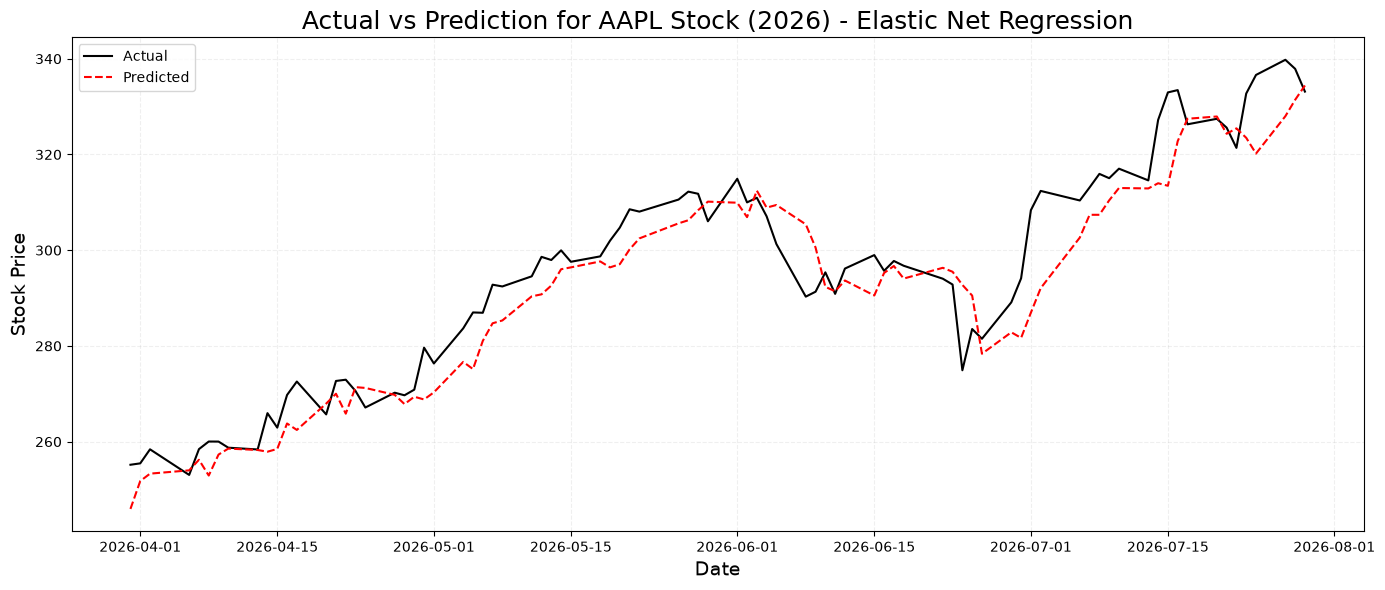

In [49]:
import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_result.index, df_result['Actual'], label = 'Actual', color = 'black') 
plt.plot(df_result.index, df_result['Predicted'], label = 'Predicted', color = 'red', linestyle = '--')
plt.title("Actual vs Prediction for AAPL Stock (2026) - Elastic Net Regression", fontsize = 18)
plt.xlabel("Date", fontsize = 14)
plt.ylabel("Stock Price", fontsize = 14)
plt.grid(True, linestyle = '--', alpha = 0.2)
plt.tight_layout()
plt.legend()
plt.show()

In [50]:
from sklearn.metrics import r2_score, mean_squared_error
r2 = r2_score(Y_test, y_pred)
print("R square", r2)
mse = mean_squared_error(Y_test, y_pred)
print("mse",mse)
rmse = np.sqrt(mse)
print("rmse", rmse)

R square 0.8905654302665411
mse 57.82536423952135
rmse 7.604299062998598
